# Drought analysis for the European State of the Climate report 2025 | spotlight section on Fennoscandia

Analysis for the spotlight section entitled 'Heatwave in Fennoscandia', showing (i) the the July / summer drought conditions over Fennoscandia and, potentially also (ii) the increased fire danger due to the drought conditions. 


In [1]:
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import cmocean
from matplotlib.colors import BoundaryNorm
from matplotlib.ticker import (MultipleLocator, AutoMinorLocator)
import matplotlib.dates as mdates
from matplotlib.dates import DateFormatter
from mpl_toolkits.basemap import Basemap
from mpl_toolkits.basemap import shiftgrid
import numpy as np
import os
import datetime as dt
import pandas as pd
import geopandas as gpd
import sys
! pip install xclim
import xclim as xclim
import calendar
import netCDF4 as nc4
import xarray as xr
# create colorscheme
from dateutil import relativedelta
from datetime import timedelta
#xr.set_options(display_expand_attrs=False)

sys.path.insert(0, '..')
sys.path.insert(0, '../..')

Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 25.1.1 -> 25.3
[notice] To update, run: pip install --upgrade pip


In [2]:
from helpers.helpers import plot_spi_timeseries, plot_precip_timeseries, create_diverging_colorscheme, plot_droughtmap
from helpers.helpers_plotting import create_diverging_colorscheme
from helpers.geodata import calculate_gridarea

In [3]:
ipath         = "/scratch/nejk/droughts_hist/"
windows       = [1,3,12]
region        = "Fennoscandia"
ref_period    = "1991to2020"
ryyyy_start   = int(ref_period[:4])
ryyyy_end     = int(ref_period[6:11])
print(ryyyy_start)
print(ryyyy_end)
#time_period   = "20220101to20240101"

1991
2020


In [14]:
# create colorscheme
spi_levels = [-3, -2, -1.5, -1, 1, 1.5, 2, 3]
plot_type  = 'pcolormesh'
cmap_spi, clevels = create_diverging_colorscheme("brown_white_green", start_color = (102/255, 51/255, 0), mid_color = (1, 1, 1), end_color = (51/255, 102/255, 0), 
                                                 levels = spi_levels, levels4pcolormesh=True if plot_type == "pcolormesh" else False)
color_list = [colors.rgb2hex(cmap_spi(i)) for i in range(cmap_spi.N)]
#print(color_list)

/usr/local/apps/python3/3.12.9-01/lib/python3.12/site-packages/gribapi/__init__.py:23: UserWarning: ecCodes 2.39.0 or higher is recommended. You are running version 2.31.0
  warnings.warn(


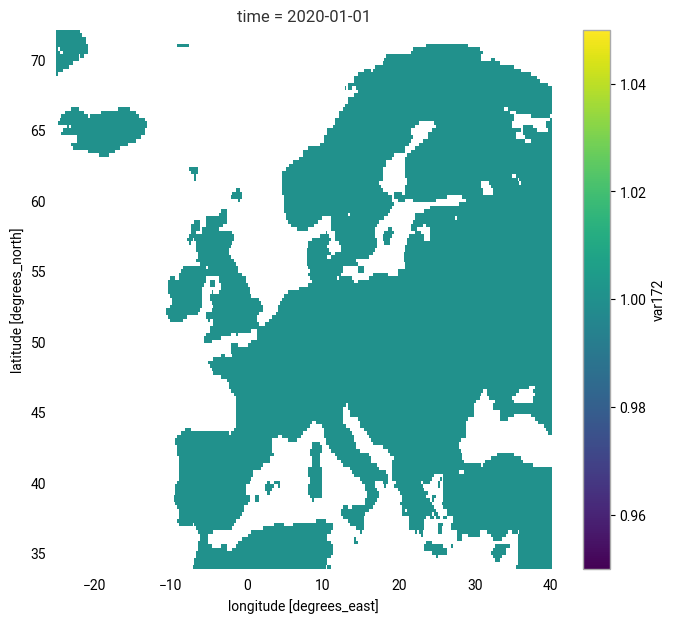

In [6]:
# read landmask
ifile_name    = "landmask_era5_europe.nc"
ifile         = os.path.join("masks", ifile_name)
varname       = "var172"
landmask = xr.open_dataset(ifile)[varname]
landmask = landmask.where( landmask.values == 1 )
landmask.plot()

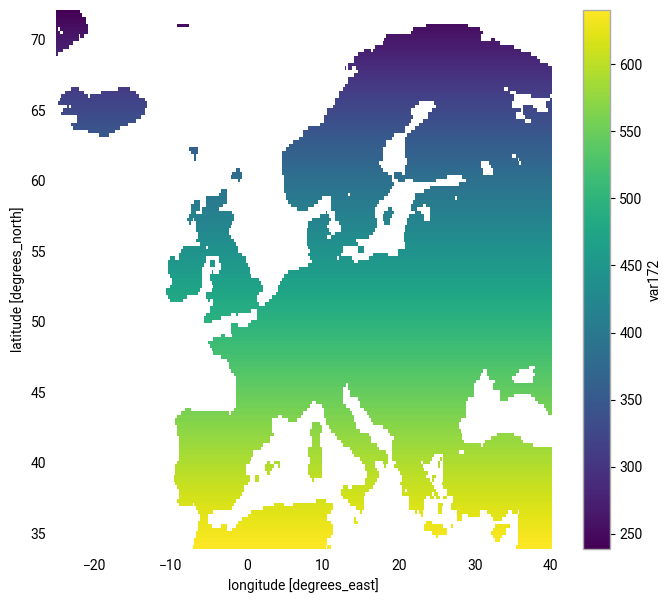

In [7]:
area_2d = calculate_gridarea(landmask.lat, res=abs(landmask.lat[1]-landmask.lat[0]), nlon=len(landmask.lon))*landmask[0,:,:]
area_2d = xr.DataArray(area_2d, coords={'lat': landmask.lat,'lon': landmask.lon}, dims=["lat", "lon"])
area_2d.plot()

dict_keys(['Europe', 'Southwestern Europe', 'Northwestern Europe', 'Southeastern Europe', 'Northeastern Europe', 'Southern Europe', 'Northern Europe'])


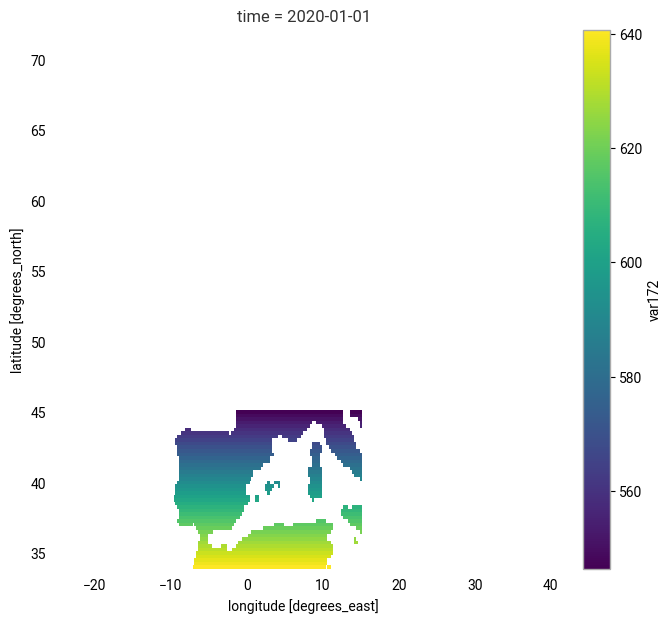

In [8]:
# subregions (extent: W/E/S/N)
esotc_regions = {'Europe':{'extent': [-25,40,34,72], 'limits':[0,20]},    
                 'Southwestern Europe':{'extent': [-25,15,34,45], 'limits':[0,45]},    
                 'Northwestern Europe':{'extent': [-25,15,45,72], 'limits':[0,20]},    
                 'Southeastern Europe':{'extent': [15,40,34,45], 'limits':[0,45]},    
                 'Northeastern Europe':{'extent': [15,40,45,72], 'limits':[0,20]},
                 'Southern Europe':{'extent': [-25,40,34,45], 'limits':[0,45]},
                 'Northern Europe':{'extent': [-25,40,45,72], 'limits':[0,20]}}
print(esotc_regions.keys())

subregions_landmask = {}
subregions_landarea = {}
for iregion in esotc_regions.keys():

    subregions_landmask[iregion] = landmask
    mask_lon = (landmask.lon >= esotc_regions[iregion]['extent'][0]) & (landmask.lon <= esotc_regions[iregion]['extent'][1])
    mask_lat = (landmask.lat >= esotc_regions[iregion]['extent'][2]) & (landmask.lat <= esotc_regions[iregion]['extent'][3])
    subregions_landmask[iregion] = subregions_landmask[iregion].where(mask_lon & mask_lat, drop=False)

    subregions_landarea[iregion] = (subregions_landmask[iregion]*area_2d).where(mask_lon & mask_lat, drop=False)#.sum()

(subregions_landmask['Southwestern Europe']*area_2d).plot()
#(subregions_landmask['Southern Europe']*area_2d).plot()
#print(subregions_landarea['Southwestern Europe'])
#print(subregions_landarea['Southwestern Europe'].sum(dim=['lat','lon']))

In [9]:
## Download ERA5-Drought 
era5d_zipfile = f"./data/era5_drought/era5_drought_estoc25.zip"

import cdsapi

dataset = "derived-drought-historical-monthly"
request = {
    "variable": [
        "standardised_precipitation_index",
        "standardised_precipitation_evapotranspiration_index"
    ],
    "accumulation_period": ["1"],
    "version": "1_0",
    "product_type": ["reanalysis"],
    "dataset_type": "consolidated_dataset",
    "year": ["2025"],
    "month": ["07"],
    "area": [71, -25, 35, 66], # N, W, S, E
}

client = cdsapi.Client()
client.retrieve(dataset, request).download(era5d_zipfile)

2026-01-22 11:48:04,046 WARNING [2025-10-30T00:00:00] Downloading data from this dataset requires that the user be registered with the CDS. The use of the API requires a CDS API key.
2026-01-22 11:48:04,047 INFO Request ID is 422e5e18-ffdb-4aea-a157-359169df8c91
2026-01-22 11:48:04,075 INFO status has been updated to accepted
2026-01-22 11:48:17,418 INFO status has been updated to running
2026-01-22 11:48:36,448 INFO status has been updated to successful


9ce00ace80531429965295418d732f09.zip:   0%|          | 0.00/858k [00:00<?, ?B/s]

'./data/era5_drought/era5_drought_estoc25.zip'

Text(0.5, 1.0, 'SPI-1, July 2025')

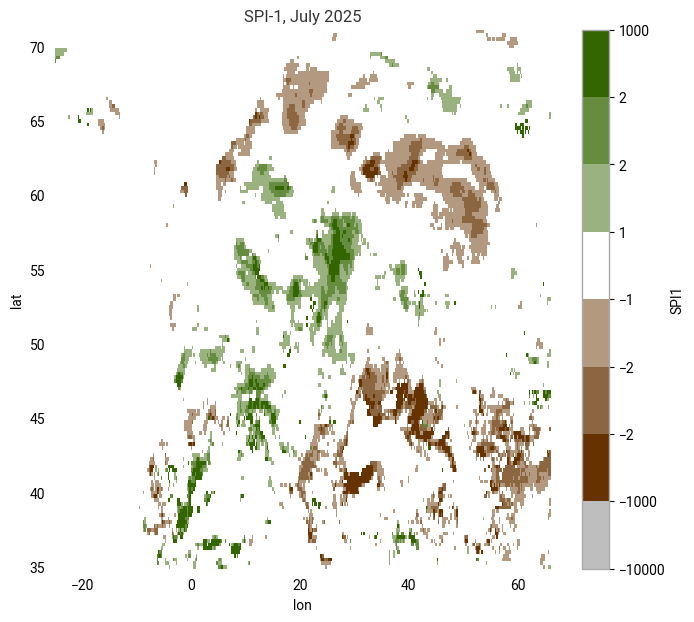

In [21]:
# test plot
import zipfile 
with zipfile.ZipFile(era5d_zipfile, 'r') as zip_ref:
    zip_ref.extractall("./data/era5_drought/")
#drought_hist = xr.open_mfdataset("./data/era5_drought/SPEI1_genlogistic_global_era5_moda_ref1991to2020_*.area-subset*.nc")
#drought_hist = xr.where(drought_hist['SPEI1'] == -9999, np.nan, drought_hist)
drought_hist = xr.open_mfdataset("./data/era5_drought/SPI1_gamma_global_era5_moda_ref1991to2020_*.area-subset*.nc")
drought_hist = xr.where(drought_hist['SPI1'] == -9999, np.nan, drought_hist)

# barren mask
vfile = "/home/nejk/code/dryfall_oper/helpers_oper/barren_mask.nc"
bmask = xr.open_dataset(vfile)
drought_hist_masked = xr.where( (bmask['barren_mask'][0,:,:] == 1) & (~np.isnan(drought_hist)) , -9999, drought_hist)

mylevels     = [-10000,-1000,-2,-1.5,-1,1,1.5,2,1000]
mycollisthex = ['#bebebe','#663300','#8c6640','#b29980','#ffffff','#99b280','#668c40','#336600']
legnames     = ["masked","extremely dry", "severely dry", "moderately dry", "near normal", "moderately wet", "severely wet", "extremely wet"]

drought_hist['SPI1'].sel(time="2025-07-01").plot(
    vmin=-3, vmax=3,
    colors=mycollisthex,
    levels=mylevels)
    #cmap=cmocean.cm.tarn)
plt.title('SPI-1, July 2025')

In [ ]:
area_3d     = area_2d.expand_dims(dim={"time": drought_hist.time}, axis=0)
landmask_3d = landmask.reindex_like(drought_hist['SPEI1'], method='nearest')
#to_plot = subregions_landarea['Southwestern Europe'].reindex_like(spi3, method="nearest")
#to_plot.sel(time="2020-08-01").plot()
#print(to_plot.sum(dim=['lat','lon']))

In [11]:
mylevels     = [-10000,-1000,-2,-1.5,-1,1,1.5,2,1000]
mycollisthex = ['#bebebe','#663300','#8c6640','#b29980','#ffffff','#99b280','#668c40','#336600']
legnames     = ["masked","extremely dry", "severely dry", "moderately dry", "near normal", "moderately wet", "severely wet", "extremely wet"]

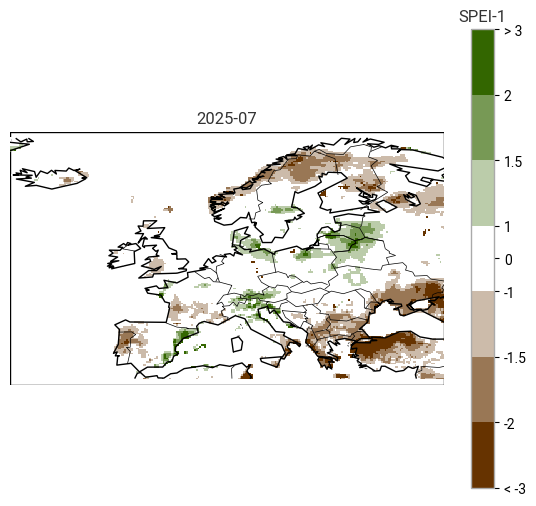

In [17]:
lats = np.asarray(drought_hist.lat)
lons = np.asarray(drought_hist.lon)
grid_lon, grid_lat = np.meshgrid(lons, lats)

stime = drought_hist.time.dt.strftime('%Y-%m').values[0]
ytime = drought_hist.time.dt.strftime('%Y').values[0]

# plot
figname = f"figures/Droughtmap_Europe_SPEI-1_{stime}.png"
to_plot = np.asarray(drought_hist["SPEI1"].sel(time=drought_hist["SPEI1"].time[0]).values)
plot_droughtmap(grid_lon, grid_lat, to_plot, 
                plot_type=plot_type,
                xlim=[-25, 40], ylim=[34, 72], zlim=[-3,3], 
                xlab="",ylab="",
                main_title=f"{stime}", legend_title=f"SPEI-1", 
                #colors=mycollisthex,
                #levels=mylevels,
                colorscheme=cmap_spi, levels=clevels, legend_ticks=[-3,-2,-1.5,-1,0,1,1.5,2,3], legend_ticklabels=["< -3",-2,-1.5,-1,0,1,1.5,2,"> 3"],
                dfigsize=(7,7), figname=figname)

    #figname = f"Droughtmap_Europe_{drought_index}-1_{stime}.png"
    #plt.savefig(figname, dpi='figure', format=None, metadata=None,
    #        bbox_inches=None, pad_inches=0.1,
    #        facecolor='auto', edgecolor='auto',
    #        backend=None)
    